In [ ]:
!nvidia-smi

Tue Nov  3 05:09:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


In [ ]:
%pip install -q "ultralytics>=8.4.0" supervision roboflow

# prevent ultralytics from tracking your activity
!yolo settings sync=False
import ultralytics
ultralytics.checks()

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.7/112.6 GB disk)


In [ ]:
!yolo task=detect mode=predict model=yolo26m.pt source=/content/image.jpg save=True verbose=False

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,411,132 parameters, 0 gradients, 68.4 GFLOPs
Results saved to /content/runs/detect/predict-2
💡 Learn more at https://docs.ultralytics.com/modes/predict


In [ ]:
!ls -la {HOME}/runs/detect/predict/

total 4956
drwxr-xr-x 2 root root    4096 Nov  3 04:36 .
drwxr-xr-x 4 root root    4096 Nov  3 05:09 ..
-rw-r--r-- 1 root root 5064617 Nov  3 04:36 image.jpg


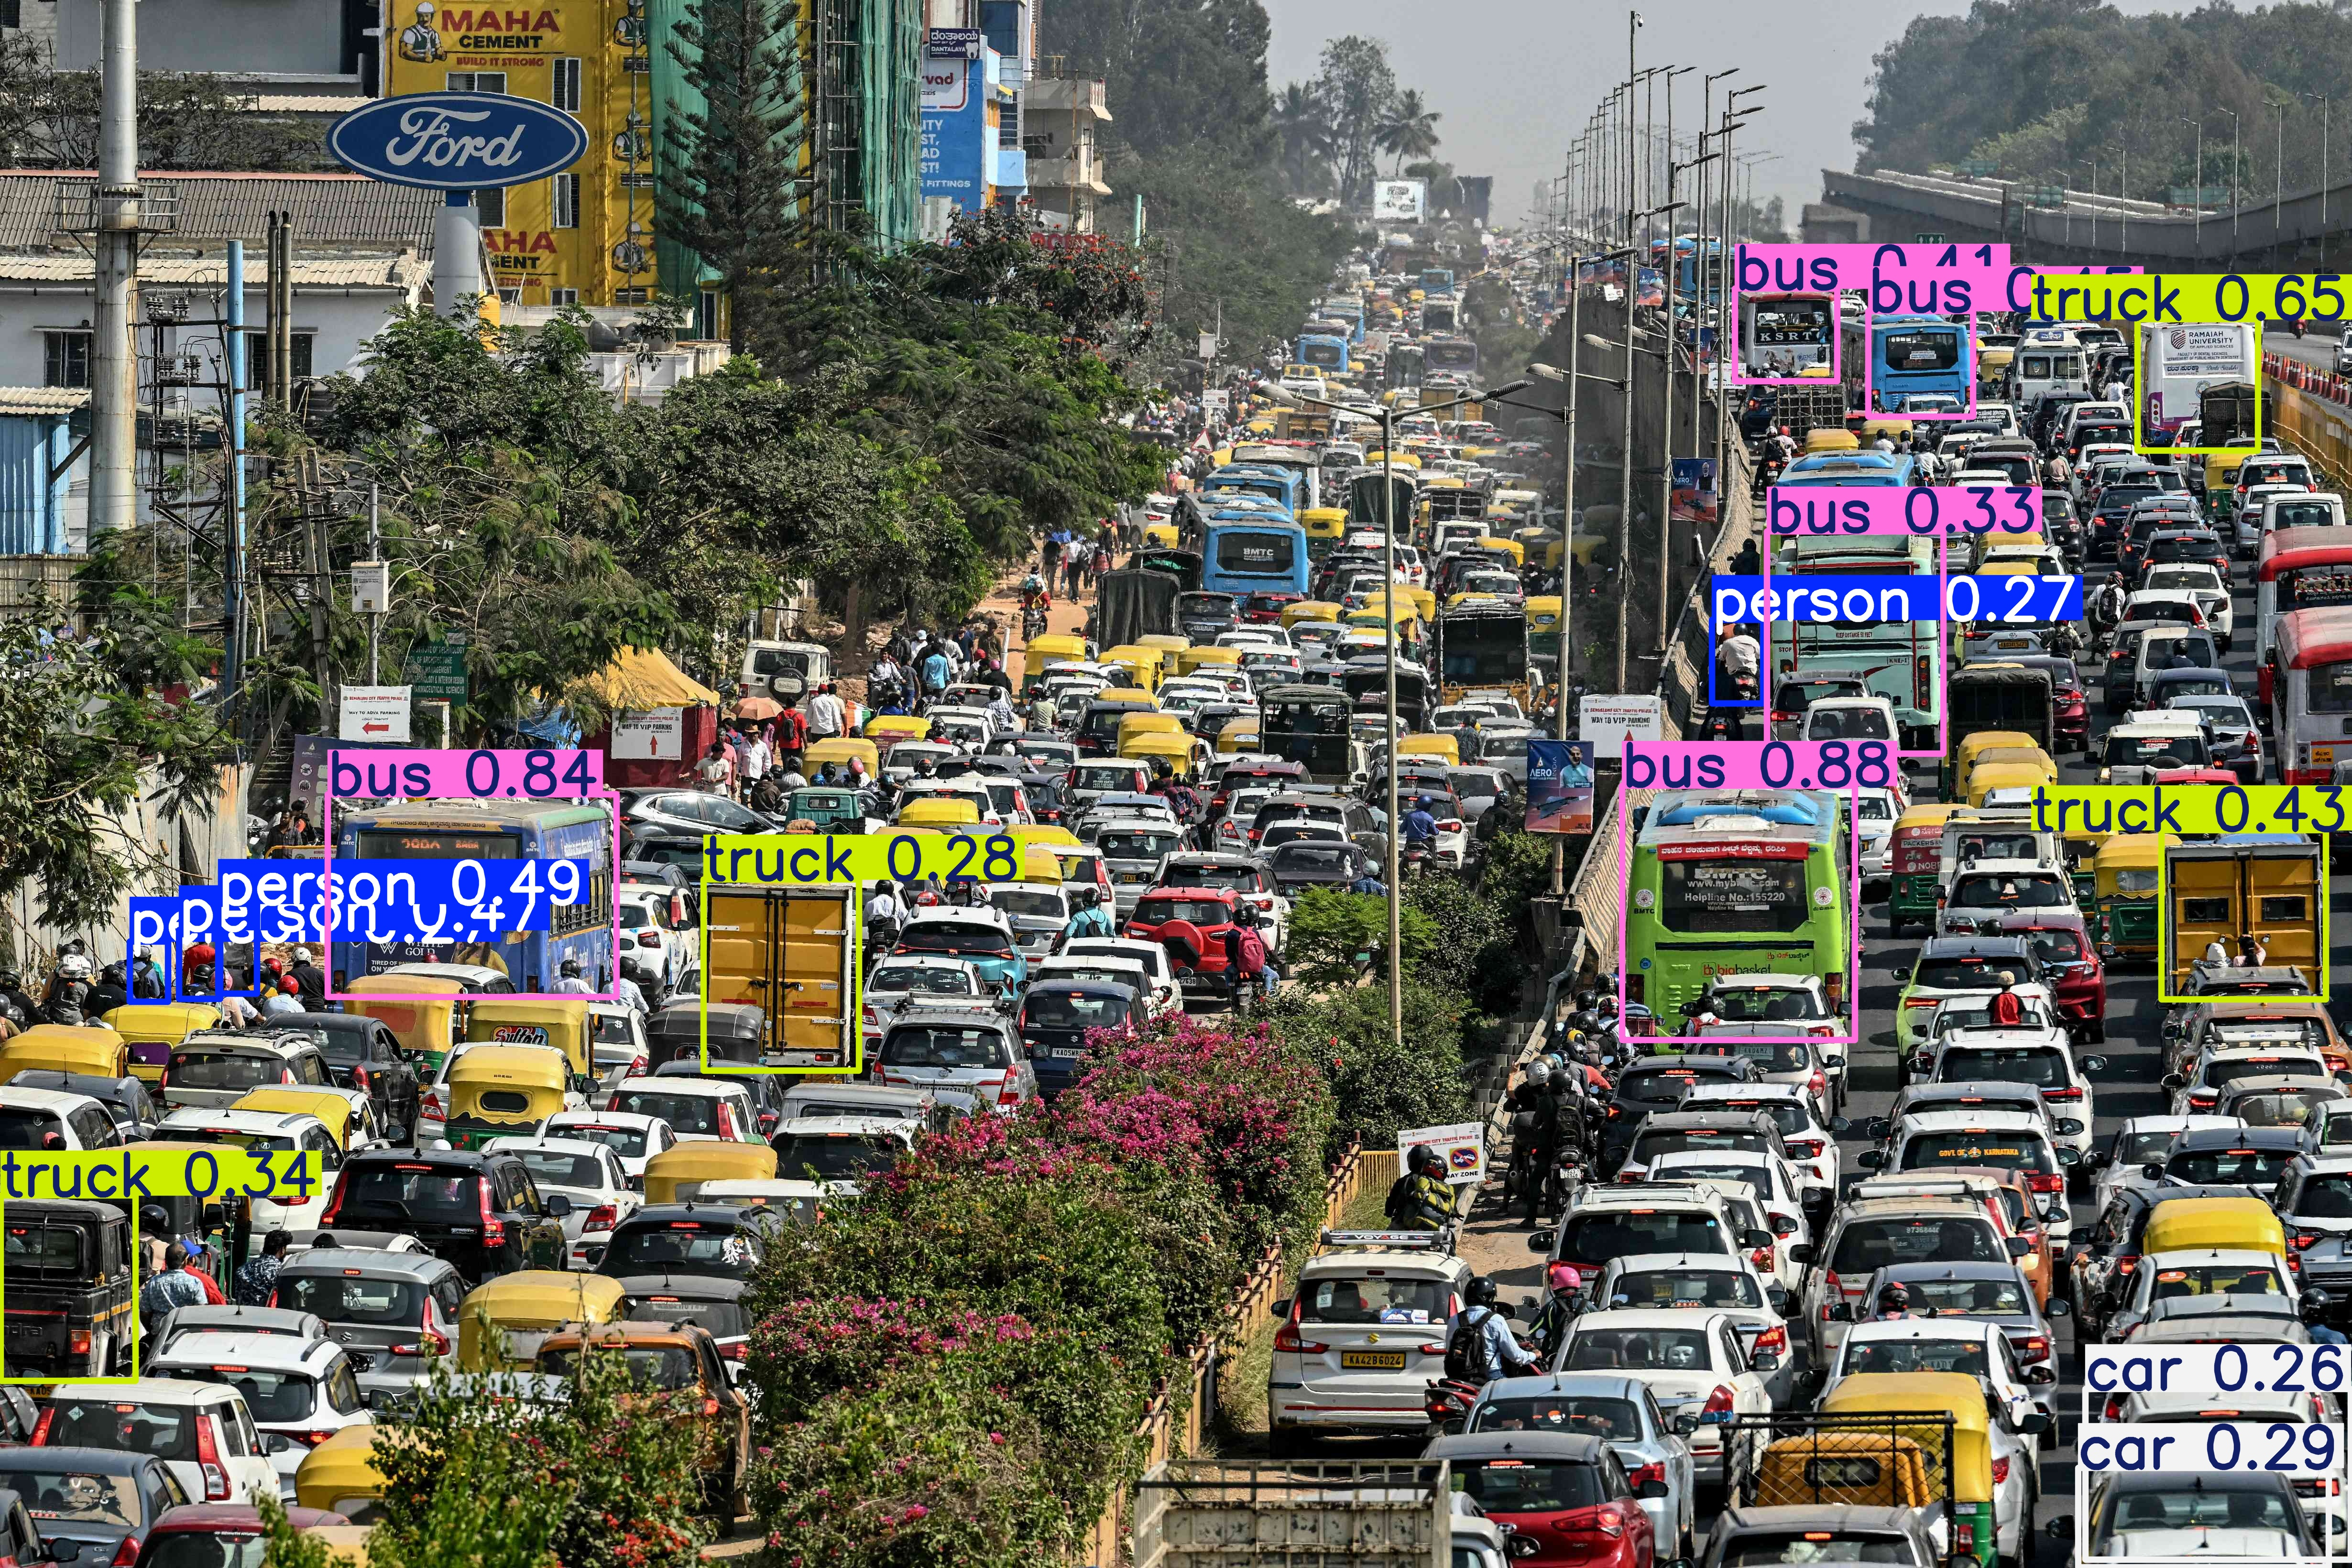

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/predict/image.jpg', width=600)

In [ ]:
!pip install -q -U ultralytics yt-dlp

In [ ]:
import subprocess
import glob
import requests
from ultralytics import YOLO
from IPython.display import Video, display

# 1. Use a highly reliable sample video URL
video_url = "https://www.w3schools.com/html/mov_bbb.mp4"
video_path = "/content/video.mp4"

# 2. Download the video using requests with a browser User-Agent header
print("Downloading sample video...")
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"}
r = requests.get(video_url, headers=headers, stream=True)
r.raise_for_status()
with open(video_path, "wb") as f:
    for chunk in r.iter_content(chunk_size=8192):
        f.write(chunk)
print("Download complete.")

# 3. Load YOLOv26m
model = YOLO("yolo26m.pt")

# 4. Detect ALL objects
model.predict(
    source=video_path,
    conf=0.25,
    imgsz=640,
    save=True,
    project="/content/runs/detect",
    name="all_objects",
    exist_ok=True,
    verbose=False
)

# 5. Find output video
files = glob.glob("/content/runs/detect/all_objects/*.mp4")
files += glob.glob("/content/runs/detect/all_objects/*.avi")

# 6. Convert output to MP4 with proper codecs for web play
subprocess.run([
    "ffmpeg", "-y", "-loglevel", "error",
    "-i", files[0],
    "-c:v", "libx264",
    "-pix_fmt", "yuv420p",
    "/content/detected_10sec.mp4"
], check=True)

# 7. Display video
display(Video("/content/detected_10sec.mp4", embed=True, width=800))

Download complete.
WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /content/runs/detect/all_objects


In [ ]:

!pip install -q -U ultralytics opencv-python

import cv2
import numpy as np
import base64
from ultralytics import YOLO
from google.colab.output import eval_js
from google.colab import output
from IPython.display import display, Javascript

# 1. Load YOLOv26m model
model = YOLO("yolo26m.pt")

# 2. Start laptop webcam in browser
display(Javascript("""
window.yoloStop = false;

window.startCamera = async function() {
    const old = document.getElementById('yolo-camera-container');
    if (old) old.remove();

    const container = document.createElement('div');
    container.id = 'yolo-camera-container';

    const video = document.createElement('video');
    video.id = 'yolo-webcam';
    video.autoplay = true;
    video.playsInline = true;
    video.muted = true;
    video.style.width = '640px';

    const canvas = document.createElement('canvas');
    canvas.id = 'yolo-output';
    canvas.width = 640;
    canvas.height = 480;
    canvas.style.width = '640px';

    const button = document.createElement('button');
    button.innerText = 'Stop Camera';
    button.onclick = () => {
        window.yoloStop = true;
        if (video.srcObject) {
            video.srcObject.getTracks().forEach(t => t.stop());
        }
    };

    container.appendChild(video);
    container.appendChild(canvas);
    container.appendChild(button);
    document.body.appendChild(container);

    const stream = await navigator.mediaDevices.getUserMedia({
        video: {width: 640, height: 480},
        audio: false
    });

    video.srcObject = stream;
    await video.play();
    return true;
};

window.captureFrame = function() {
    if (window.yoloStop) return null;

    const video = document.getElementById('yolo-webcam');
    const canvas = document.createElement('canvas');

    canvas.width = 640;
    canvas.height = 480;

    const ctx = canvas.getContext('2d');
    ctx.drawImage(video, 0, 0, 640, 480);

    return canvas.toDataURL('image/jpeg', 0.7);
};

window.showDetection = function(data) {
    const canvas = document.getElementById('yolo-output');
    if (!canvas) return;

    const ctx = canvas.getContext('2d');
    const img = new Image();

    img.onload = () => {
        ctx.drawImage(img, 0, 0, 640, 480);
    };

    img.src = data;
};
"""))

# 3. Activate camera
eval_js("startCamera()")

print("Webcam started. Detecting all objects...")

# 4. Continuous detection
while True:
    frame_data = eval_js("captureFrame()")

    if frame_data is None:
        print("Camera stopped.")
        break

    # Decode webcam frame
    encoded = frame_data.split(",")[1]
    image_bytes = base64.b64decode(encoded)

    frame = cv2.imdecode(
        np.frombuffer(image_bytes, np.uint8),
        cv2.IMREAD_COLOR
    )

    # YOLO detection - ALL objects
    results = model.predict(
        frame,
        conf=0.25,
        imgsz=640,
        verbose=False
    )

    # Draw bounding boxes and labels
    annotated = results[0].plot()

    # Encode processed frame
    _, buffer = cv2.imencode(".jpg", annotated)
    output_data = base64.b64encode(buffer).decode("utf-8")

    # Display in Colab
    eval_js(
        "showDetection('data:image/jpeg;base64,"
        + output_data + "')"
    )


<IPython.core.display.Javascript object>

Webcam started. Detecting all objects...
Camera stopped.


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="1zhELCaXTMCBAi1baJhy")
project = rf.workspace("jakob-awn1e").project("invoice-detection")
version = project.version(28)
dataset = version.download("yolo26")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Invoice-Detection-28 in yolo26:: 100%|██████████| 1509/1509 [00:05<00:00, 261.75it/s]


In [ ]:
%cd {HOME}

!yolo task=detect mode=train model=yolo26m.pt data={dataset.location}/data.yaml epochs=5 imgsz=640 plots=True

/content
Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Invoice-Detection-28/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optim

In [ ]:
!ls "/content/runs/detect/train"

args.yaml			 labels.jpg		val_batch0_pred.jpg
BoxF1_curve.png			 results.csv		val_batch1_labels.jpg
BoxP_curve.png			 results.png		val_batch1_pred.jpg
BoxPR_curve.png			 train_batch0.jpg	val_batch2_labels.jpg
BoxR_curve.png			 train_batch1.jpg	val_batch2_pred.jpg
confusion_matrix_normalized.png  train_batch2.jpg	weights
confusion_matrix.png		 val_batch0_labels.jpg


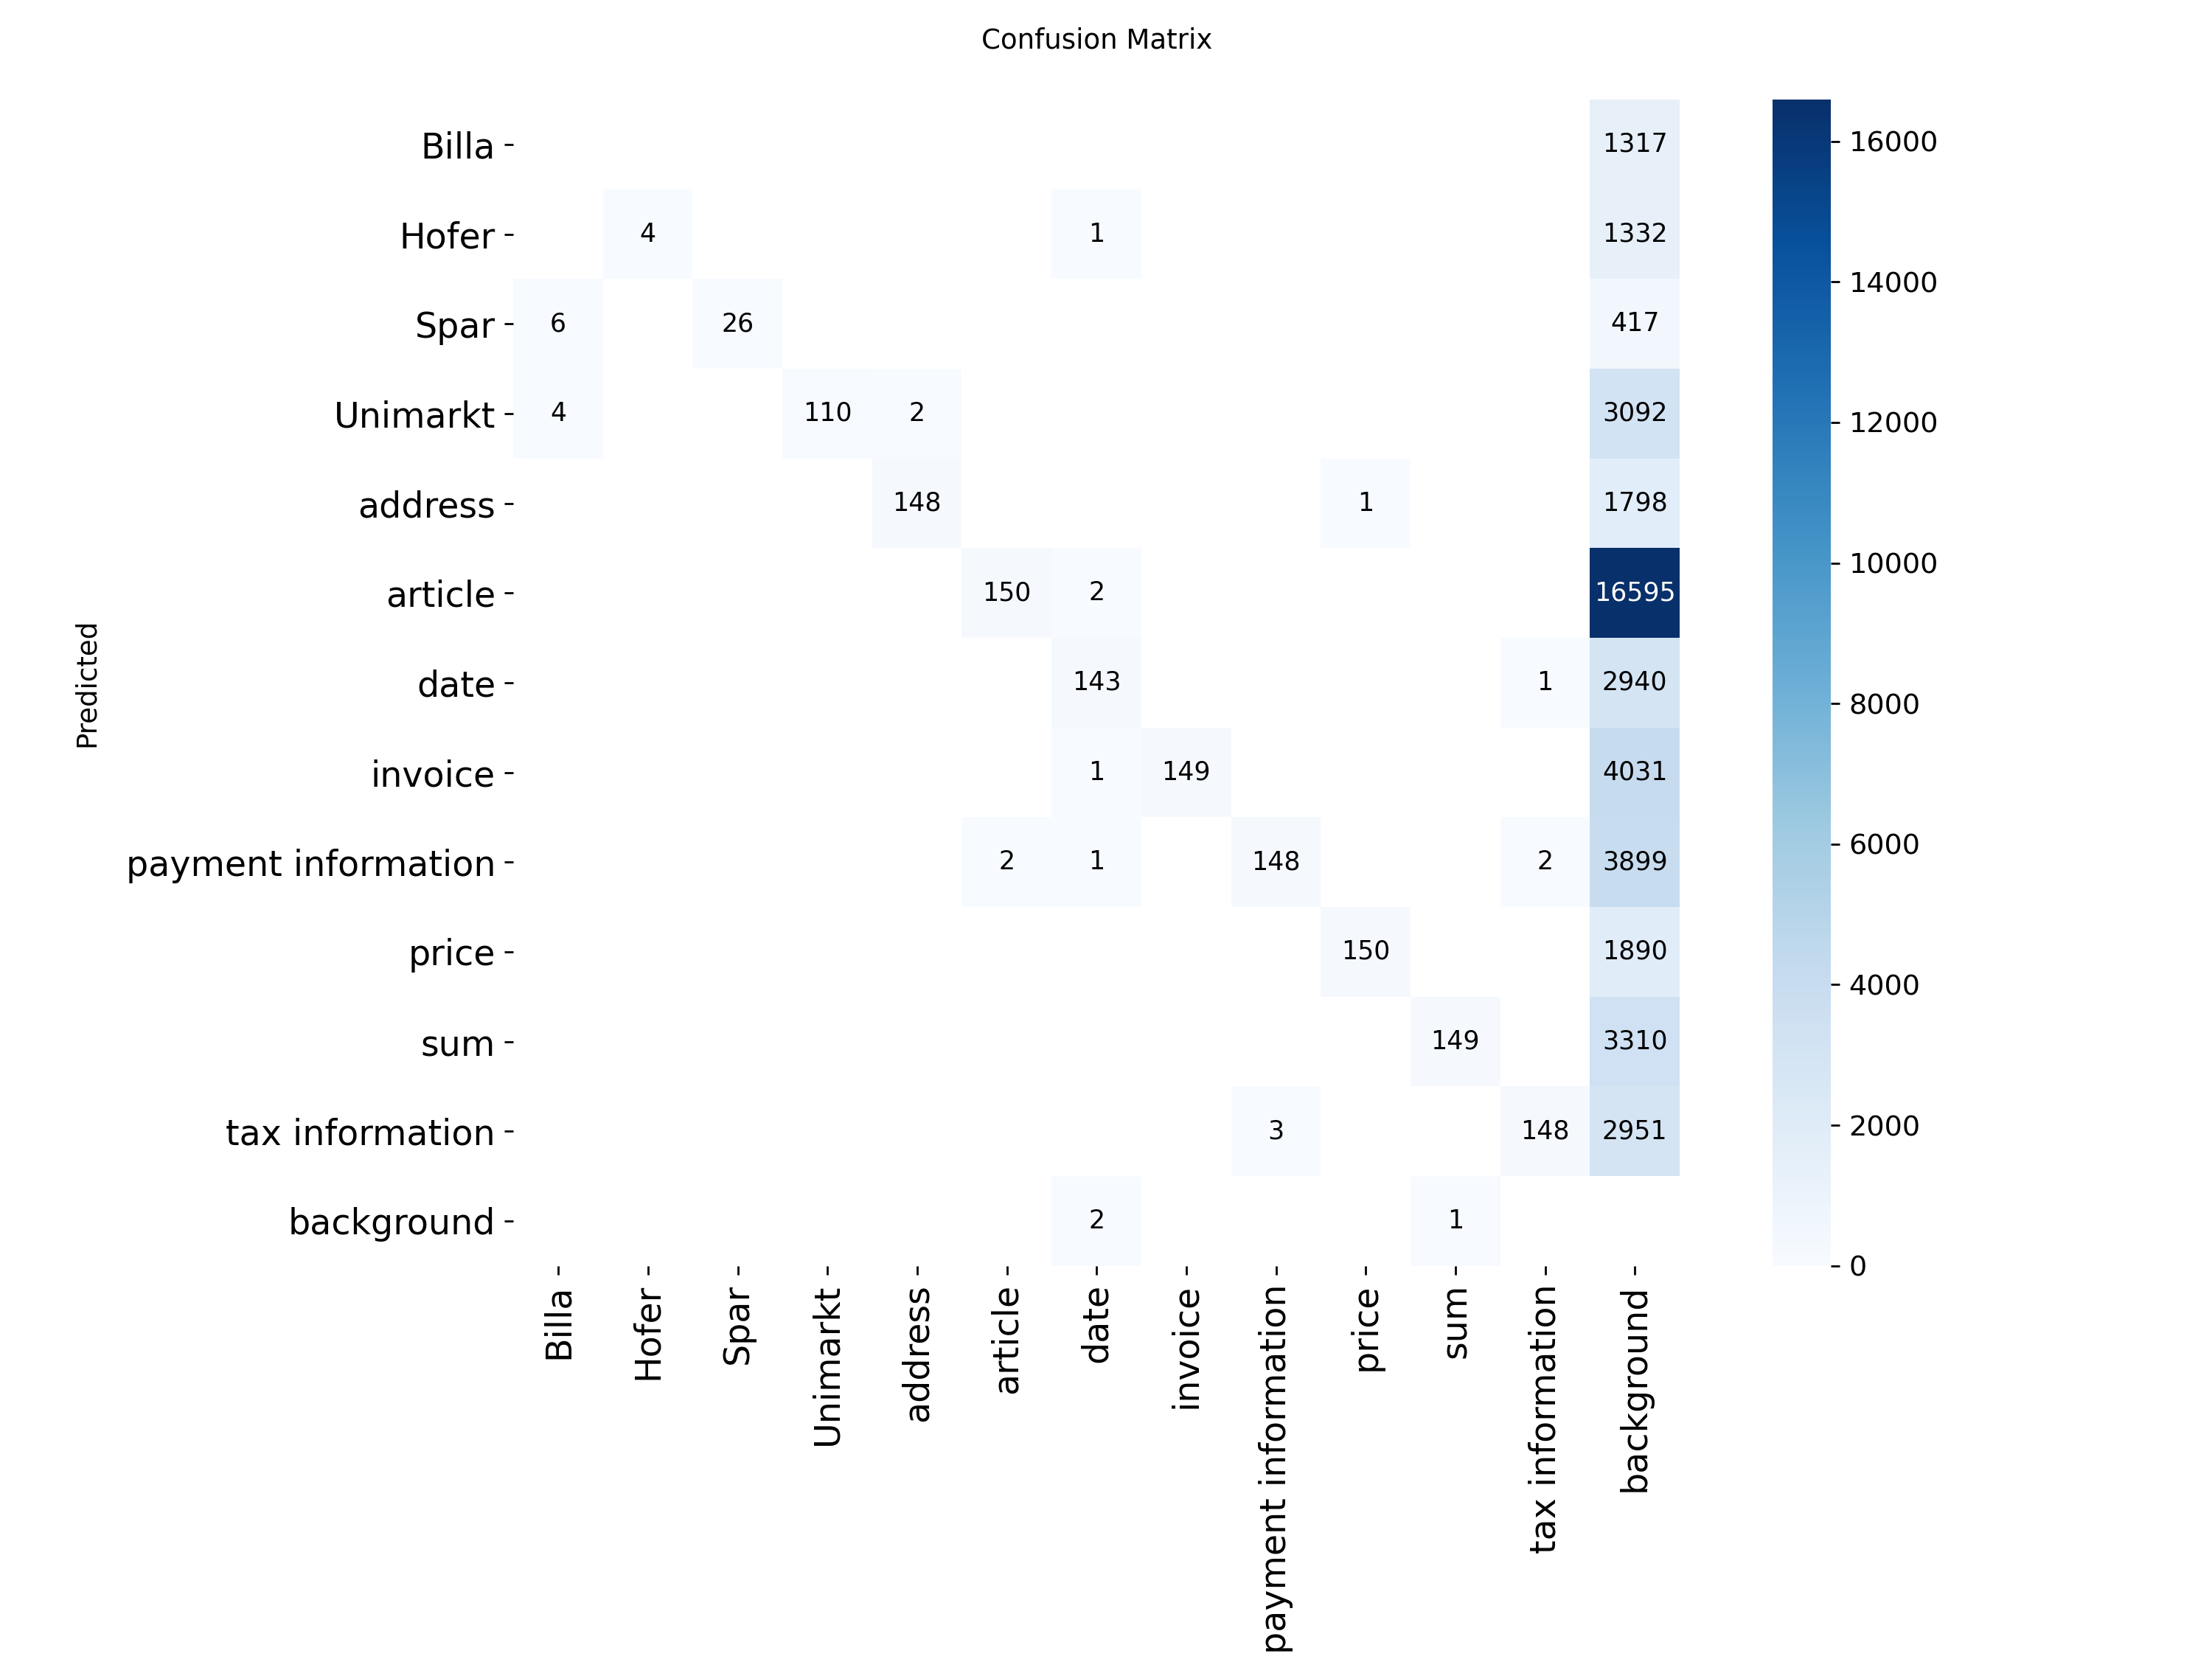

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'/content/runs/detect/train/confusion_matrix.png', width=600)

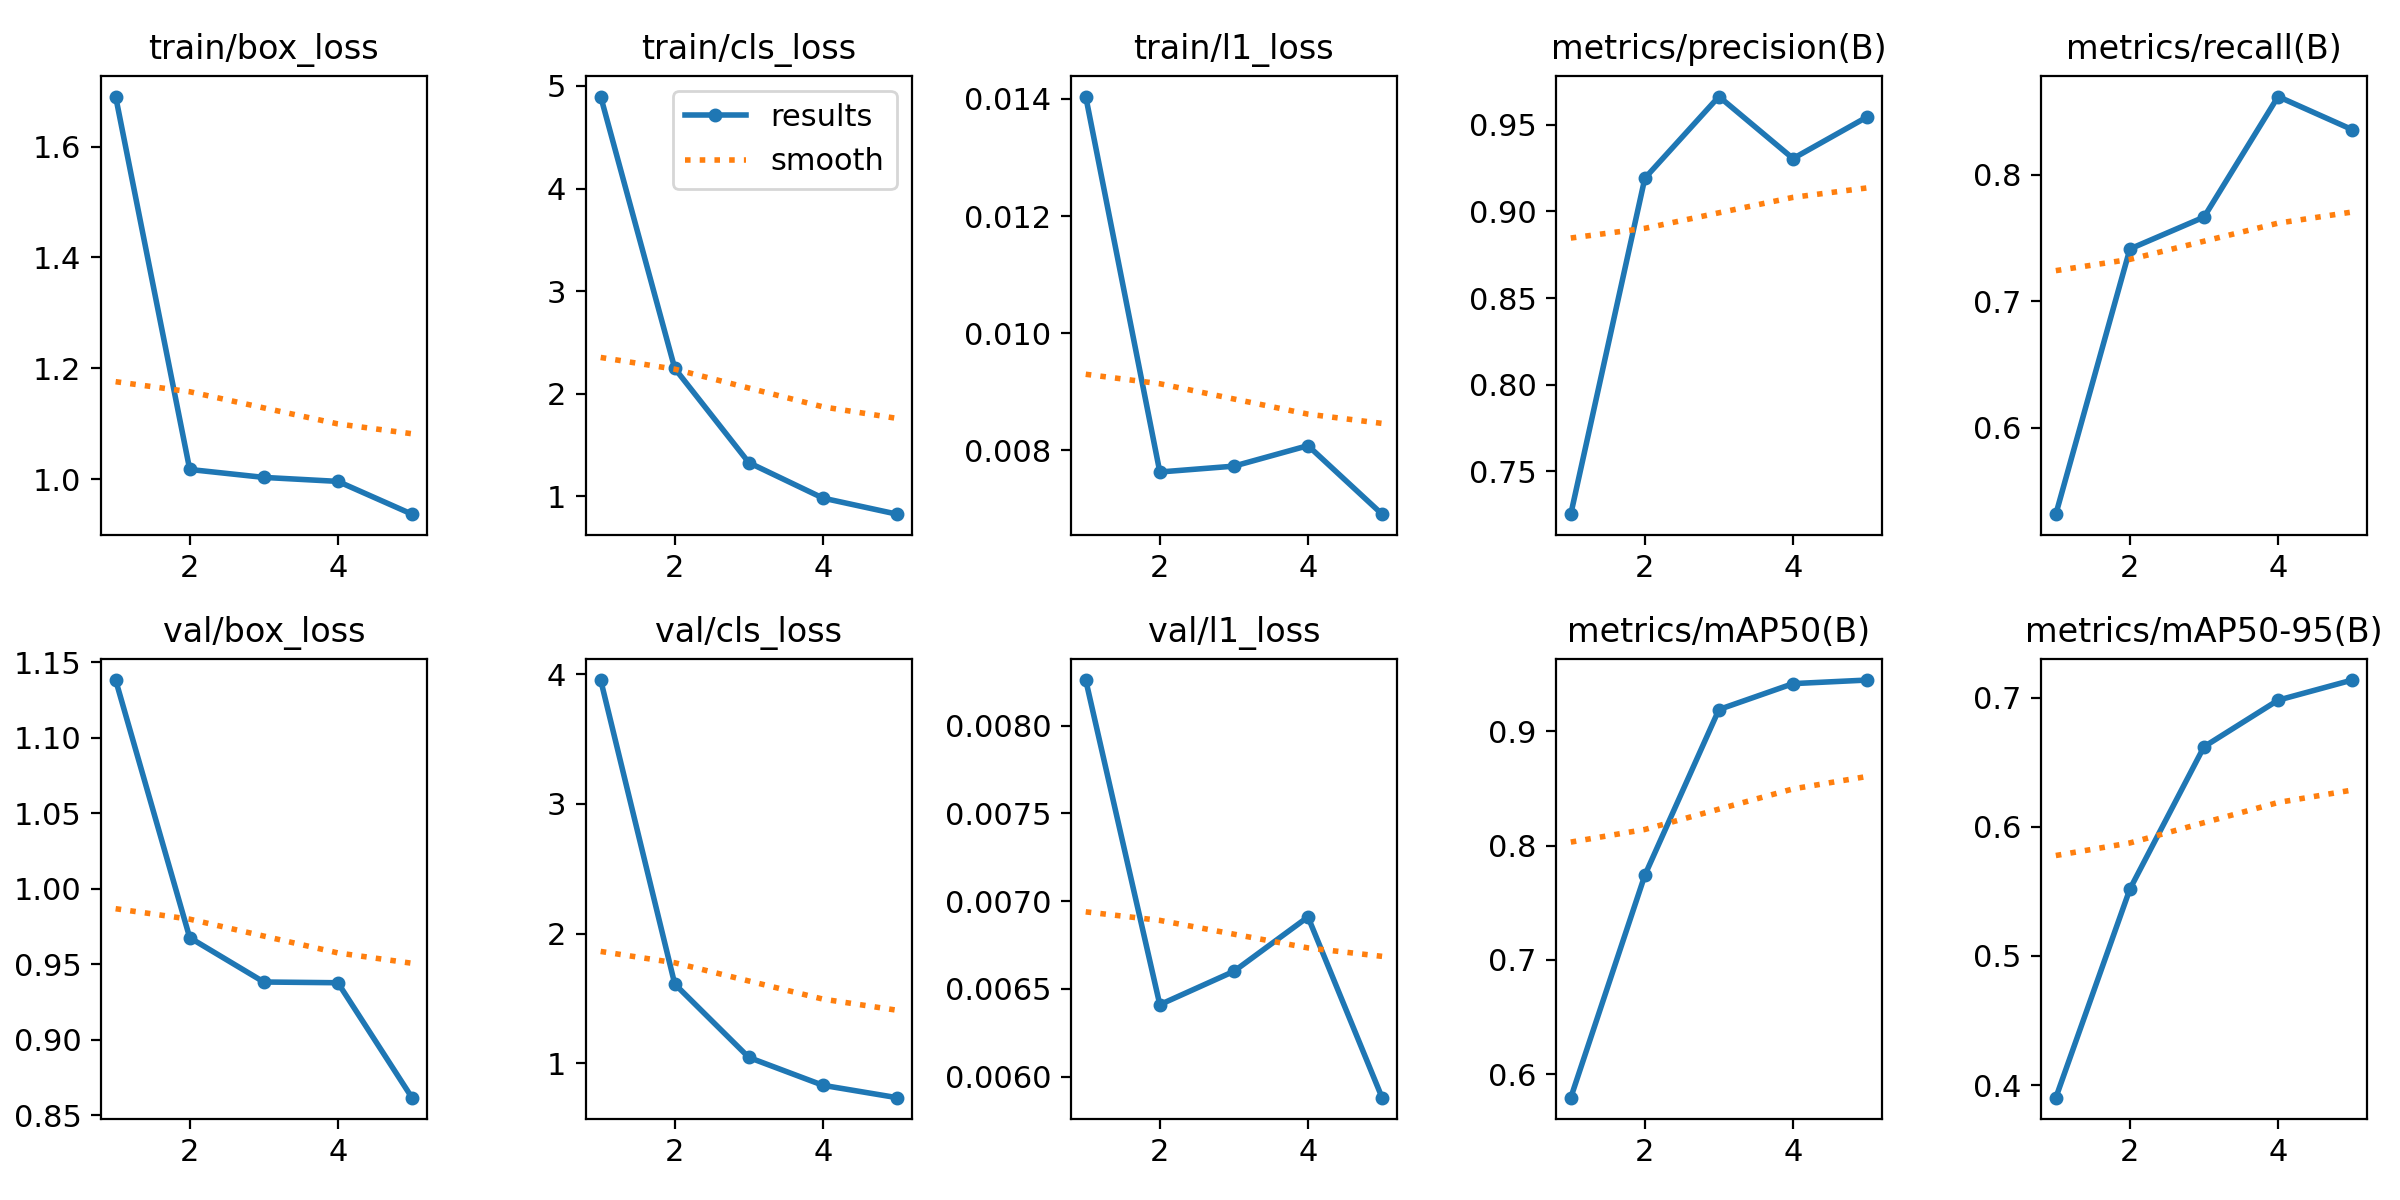

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'/content/runs/detect/train/results.png', width=600)

In [ ]:

from google.colab import drive
import shutil
import os

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Source folder path
source = "/content/runs"

# 3. Destination folder path
destination = "/content/drive/MyDrive/001_Yolov8"

# 4. Create destination parent directory
os.makedirs(os.path.dirname(destination), exist_ok=True)

# 5. Copy folder with all files and subfolders
shutil.copytree(
    source,
    destination,
    dirs_exist_ok=True
)

print("Folder copied successfully!")
print("Source:", source)
print("Destination:", destination)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder copied successfully!
Source: /content/runs
Destination: /content/drive/MyDrive/001_Yolov8


In [ ]:
!ls "/content/drive/MyDrive/001_Yolov8"

detect
